In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score

from src.data import load_trips
from src.pipeline import FINAL_GROUPS, logistic, make_features, tree

trips = load_trips()
train = trips[trips["split"] == "train"]
valid = trips[trips["split"] == "valid"]
X_train, y_train = make_features(train), train["is_crawl"]
X_valid, y_valid = make_features(valid), valid["is_crawl"]

model = logistic(FINAL_GROUPS)
model.fit(X_train, y_train)
p_valid = model.predict_proba(X_valid)[:, 1]

pr_auc = average_precision_score(y_valid, p_valid)
print(round(pr_auc, 3), round(pr_auc / y_valid.mean(), 3))

0.632 3.321


In [2]:
COST_MISSED_CRAWL = 3
COST_FALSE_ALARM = 1

n = len(y_valid)
rows = []
for t in np.arange(0.05, 0.96, 0.01):
    pred = p_valid >= t
    tp = int((pred & (y_valid == 1)).sum())
    fp = int((pred & (y_valid == 0)).sum())
    fn = int((~pred & (y_valid == 1)).sum())
    rows.append({
        "threshold": round(t, 2),
        "warned_%": round(pred.mean() * 100, 1),
        "precision": tp / (tp + fp) if tp + fp else 0,
        "recall": tp / (tp + fn),
        "fp": fp,
        "fn": fn,
        "cost_per_trip": (COST_MISSED_CRAWL * fn + COST_FALSE_ALARM * fp) / n,
    })
curve = pd.DataFrame(rows)

best = curve.loc[curve["cost_per_trip"].idxmin()]
THRESHOLD = float(best["threshold"])
print(best.round(3))

print("\nNever warn:", round(COST_MISSED_CRAWL * y_valid.mean(), 3))
print("Always warn:", round(COST_FALSE_ALARM * (1 - y_valid.mean()), 3))

print("\nBest threshold for other cost ratios:")
for c_fn in [2, 3, 5]:
    cost = c_fn * curve["fn"] + curve["fp"]
    print(f"missed crawl costs {c_fn}x a false alarm -> threshold", curve.loc[cost.idxmin(), "threshold"])

threshold            0.300
warned_%            27.000
precision            0.509
recall               0.723
fp               25212.000
fn               10016.000
cost_per_trip        0.291
Name: 25, dtype: float64

Never warn: 0.571
Always warn: 0.81

Best threshold for other cost ratios:
missed crawl costs 2x a false alarm -> threshold 0.37
missed crawl costs 3x a false alarm -> threshold 0.3
missed crawl costs 5x a false alarm -> threshold 0.19


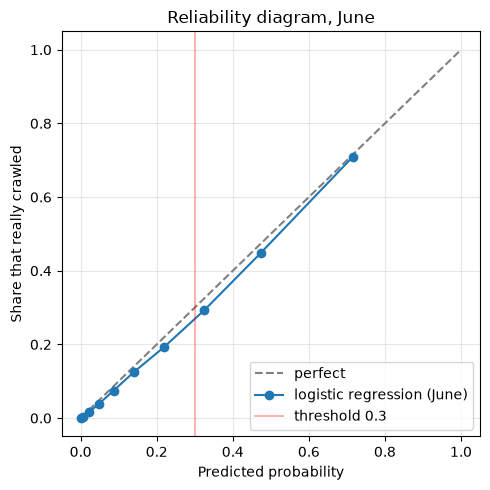

   predicted  observed
0      0.001     0.000
1      0.007     0.004
2      0.023     0.017
3      0.049     0.039
4      0.087     0.075
5      0.141     0.126
6      0.218     0.192
7      0.326     0.293
8      0.474     0.449
9      0.715     0.709


In [3]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

FIG_DIR = ROOT / "reports" / "figures"

frac_pos, mean_pred = calibration_curve(y_valid, p_valid, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect")
ax.plot(mean_pred, frac_pos, marker="o", label="logistic regression (June)")
ax.axvline(THRESHOLD, color="red", alpha=0.3, label=f"threshold {THRESHOLD}")
ax.set(xlabel="Predicted probability", ylabel="Share that really crawled", title="Reliability diagram, June")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "reliability_june.png", dpi=150)
plt.show()

print(pd.DataFrame({"predicted": mean_pred, "observed": frac_pos}).round(3))

In [4]:
lookup = pd.read_csv(ROOT / "data" / "raw" / "taxi_zone_lookup.csv")
borough = valid["PULocationID"].map(lookup.set_index("LocationID")["Borough"])
pred = p_valid >= THRESHOLD


def by_slice(label, groups):
    df = pd.DataFrame({"group": groups.values, "y": y_valid.values, "pred": pred})
    rows = []
    for g, d in df.groupby("group", observed=True):
        warned = int(d["pred"].sum())
        tp = int((d["pred"] & (d["y"] == 1)).sum())
        rows.append({
            "slice": label,
            "group": g,
            "trips": len(d),
            "crawl_rate_%": round(d["y"].mean() * 100, 1),
            "warned_%": round(d["pred"].mean() * 100, 1),
            "precision": round(tp / warned, 3) if warned else np.nan,
            "recall": round(tp / d["y"].sum(), 3) if d["y"].sum() else np.nan,
        })
    return pd.DataFrame(rows)


hour = X_valid["hour"]
slices = [
    by_slice("overall", pd.Series("all trips", index=valid.index)),
    by_slice("payment", valid["payment_type"].eq(0).map({True: "flex fare", False: "not flex"})),
    by_slice("hour", pd.cut(hour, [-1, 6, 9, 18, 23], labels=["0-6h", "7-9h", "10-18h", "19-23h"])),
    by_slice("day", (X_valid["day_of_week"] >= 5).map({True: "weekend", False: "weekday"})),
    by_slice("distance", pd.cut(X_valid["trip_distance"], [0, 0.5, 1, 2, 4, 100], labels=["<0.5", "0.5-1", "1-2", "2-4", ">4"])),
    by_slice("airport", X_valid["airport_trip"].map({1: "airport trip", 0: "no airport"})),
    by_slice("pickup borough", borough.fillna("Unknown")),
]
pd.concat(slices, ignore_index=True)

,slice,group,trips,crawl_rate_%,warned_%,precision,recall
0,overall,all trips,190003,19.0,27.0,0.509,0.723
1,payment,flex fare,48170,12.1,13.0,0.558,0.602
2,payment,not flex,141833,21.4,31.8,0.502,0.746
3,hour,0-6h,22622,3.4,1.7,0.254,0.131
4,hour,7-9h,20978,14.5,17.5,0.487,0.590
5,hour,10-18h,92987,28.1,44.0,0.521,0.816
6,hour,19-23h,53416,11.8,12.0,0.465,0.474
7,day,weekday,138584,21.5,31.8,0.523,0.775
8,day,weekend,51419,12.4,14.1,0.424,0.482
9,distance,<0.5,9546,57.4,75.2,0.661,0.868


In [5]:
from sklearn.tree import DecisionTreeClassifier

BASE_COLS = ["hour", "day_of_week", "trip_distance"]
baseline = DecisionTreeClassifier(max_depth=2, random_state=42)
baseline.fit(X_train[BASE_COLS], y_train)
base_valid = baseline.predict_proba(X_valid[BASE_COLS])[:, 1]
print("Baseline on June, PR AUC:", round(average_precision_score(y_valid, base_valid), 3))

Baseline on June, PR AUC: 0.339


In [6]:
test = trips[trips["split"] == "test"]
X_test, y_test = make_features(test), test["is_crawl"].to_numpy()
p_test = model.predict_proba(X_test)[:, 1]
base_test = baseline.predict_proba(X_test[BASE_COLS])[:, 1]


def july_metrics(y, p, b):
    pred = p >= THRESHOLD
    tp = int((pred & (y == 1)).sum())
    fp = int((pred & (y == 0)).sum())
    fn = int((~pred & (y == 1)).sum())
    ap = average_precision_score(y, p)
    ap_base = average_precision_score(y, b)
    return {
        "model_pr_auc": ap,
        "model_lift": ap / y.mean(),
        "baseline_pr_auc": ap_base,
        "baseline_lift": ap_base / y.mean(),
        "gain_pr_auc": ap - ap_base,
        "precision": tp / (tp + fp) if tp + fp else 0.0,
        "recall": tp / (tp + fn),
        "cost_per_trip": (COST_MISSED_CRAWL * fn + COST_FALSE_ALARM * fp) / len(y),
    }


point = july_metrics(y_test, p_test, base_test)

rng = np.random.default_rng(42)
n = len(y_test)
boot = pd.DataFrame([
    july_metrics(y_test[idx], p_test[idx], base_test[idx])
    for idx in (rng.integers(0, n, n) for _ in range(500))
])

summary = pd.DataFrame({
    "july": pd.Series(point),
    "ci_low": boot.quantile(0.025),
    "ci_high": boot.quantile(0.975),
}).round(3)
print("July trips:", n, "| positive rate:", round(y_test.mean(), 3))
summary

July trips: 189444 | positive rate: 0.168


,july,ci_low,ci_high
model_pr_auc,0.627,0.621,0.632
model_lift,3.728,3.692,3.769
baseline_pr_auc,0.327,0.324,0.331
baseline_lift,1.947,1.931,1.964
gain_pr_auc,0.299,0.295,0.304
precision,0.465,0.460,0.469
recall,0.779,0.775,0.784
cost_per_trip,0.262,0.259,0.265
